# Domain Shift and Uncertainty in a Vision Transformer for Blood Cell Classification

## Step 1: Setup and data

We use **BloodMNIST**, a public dataset of ~17,000 microscope images of blood cells in 8 classes (e.g., neutrophils, lymphocytes, platelets). It is part of the MedMNIST benchmark, which provides standardized, pre-split medical imaging datasets.

Blood cell images are a natural fit for studying domain shift. Different labs use different staining, microscopes, and cameras, so the same cell type can look different in color, sharpness, and noise from one hospital to another. A model trained in one lab may silently fail in another.

We download the images at 64×64 pixels to keep things fast, and we fix all random seeds so results are reproducible.

In [1]:
!pip install -q medmnist timm

import random, time
import numpy as np
import torch
import medmnist
from medmnist import INFO

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(0)

DATA_FLAG = "bloodmnist"
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info["python_class"])
print(info["description"], "\n")
print("Classes:", info["label"])

raw = {split: DataClass(split=split, download=True, size=64) for split in ["train", "val", "test"]}
for split, ds in raw.items():
    print(f"{split:5s}: {len(ds)} images, size {ds[0][0].size}")
print("Train images per class:", np.bincount(raw["train"].labels.ravel()))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.9 MB/s eta 0:00:00
Device: cuda Tesla T4
The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized into 3×28×28. 

Classes: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}


100%|██████████| 156M/156M [01:08<00:00, 2.29MB/s]


train: 11959 images, size (64, 64)
val  : 1712 images, size (64, 64)
test : 3421 images, size (64, 64)
Train images per class: [ 852 2181 1085 2026  849  993 2330 1643]


## Step 2: Persistent storage on Google Drive

Colab runtimes can disconnect, and everything in memory is lost when they do. To protect our work, all checkpoints (saved model weights) and results are written to a project folder on Google Drive.

Checkpoints are saved *atomically*: we first write to a temporary file, then rename it. If the runtime disconnects in the middle of saving, the previous checkpoint stays intact instead of being left half-written and corrupted.

In [8]:
import os

PROJECT_DIR = "/content/drive/MyDrive/bloodmnist_vit"
CKPT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
for d in [CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

def save_checkpoint(model, optimizer, epoch, metrics, name="last.pt"):
    path = os.path.join(CKPT_DIR, name)
    tmp = path + ".tmp"
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "epoch": epoch, "metrics": metrics}, tmp)
    os.replace(tmp, path)          # rename: the old file is only replaced once the new one is complete
    print(f"Saved checkpoint: {name} (epoch {epoch})")

def load_checkpoint(model, optimizer=None, name="last.pt"):
    path = os.path.join(CKPT_DIR, name)
    if not os.path.exists(path):
        print(f"No checkpoint '{name}' found, starting fresh.")
        return 0, {}
    ckpt = torch.load(path, map_location=device, weights_only=False)   # our own file, so trusted
    model.load_state_dict(ckpt["model"])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt["optimizer"])
    print(f"Loaded checkpoint: {name} (epoch {ckpt['epoch']})")
    return ckpt["epoch"], ckpt["metrics"]

print("Project folder:", PROJECT_DIR)
print("Contents:", os.listdir(PROJECT_DIR))

Project folder: /content/drive/MyDrive/bloodmnist_vit
Contents: ['checkpoints', 'results']


## Step 3: Pretrained Vision Transformer

We use **ViT-Small** (patch size 16, 224×224 input, ~22M parameters) from the `timm` library. It was pre-trained on ImageNet-21k and fine-tuned on ImageNet-1k. It is about 4× smaller than ViT-Base, which keeps training fast on a free T4 GPU.

Its original classification head predicts 1,000 ImageNet classes. `timm` replaces it with a new, randomly initialized head with 8 outputs, one per blood cell type. Fine-tuning then adapts the whole network to our task.

We also turn on **dropout** (10%) inside the Transformer blocks and before the head. This regularizes training, and it is required for **Monte Carlo Dropout** later: a model can only produce meaningful uncertainty from dropout at test time if it was trained with dropout.

In [4]:
import timm

assert device == "cuda", "No GPU! Switch the runtime to T4 GPU first."

MODEL_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"
NUM_CLASSES = len(info["label"])

model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                          drop_rate=0.1, proj_drop_rate=0.1).to(device)

MEAN, STD = model.pretrained_cfg["mean"], model.pretrained_cfg["std"]
print("Normalization mean/std:", MEAN, STD)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")
print("New classifier head:", model.head)

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Normalization mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
Parameters: 21.7 M
New classifier head: Linear(in_features=384, out_features=8, bias=True)


## Step 4: Data pipeline

Images are loaded at 64×64 and converted to tensors with values in [0, 1]. Resizing to 224×224 and normalizing happen on the GPU in a single `prepare` function, which is much faster than doing it image by image on the CPU.

`prepare` also has an optional `shift` argument. Later, we use it to apply simulated domain shifts (blur, noise, color changes) to the raw [0, 1] images, *before* resizing and normalization. This mimics a different microscope or staining protocol at acquisition time.

During training only, images are randomly flipped horizontally and vertically. Blood cells have no natural "up" or "left", so flipped images are still valid examples. This **data augmentation** gives the model more variety and reduces overfitting.

Raw batch: (64, 3, 64, 64) values 0.07 to 1.00
Prepared batch: (64, 3, 224, 224)


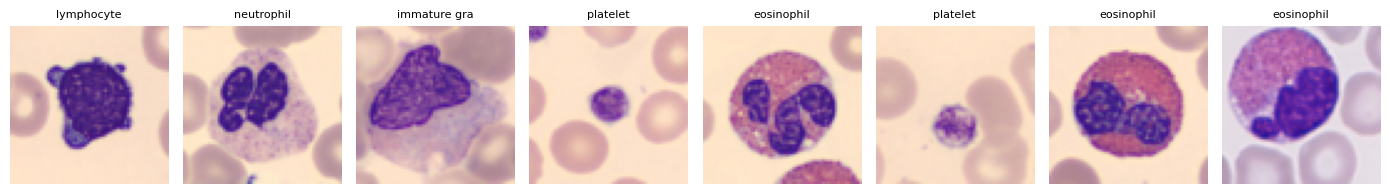

In [5]:
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

train_tf = transforms.Compose([transforms.RandomHorizontalFlip(),
                               transforms.RandomVerticalFlip(),
                               transforms.ToTensor()])
eval_tf = transforms.ToTensor()
to_label = lambda y: int(y[0])

ds = {split: DataClass(split=split, size=64, download=True, target_transform=to_label,
                       transform=train_tf if split == "train" else eval_tf)
      for split in ["train", "val", "test"]}

loaders = {
    "train": DataLoader(ds["train"], batch_size=64, shuffle=True, num_workers=2,
                        generator=torch.Generator().manual_seed(0)),
    "val":   DataLoader(ds["val"],  batch_size=256, shuffle=False, num_workers=2),
    "test":  DataLoader(ds["test"], batch_size=256, shuffle=False, num_workers=2),
}

mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std_t  = torch.tensor(STD,  device=device).view(1, 3, 1, 1)

def prepare(x, shift=None):
    x = x.to(device, non_blocking=True)
    if shift is not None:
        x = shift(x).clamp(0, 1)                     # simulated domain shift on raw images
    x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
    return (x - mean_t) / std_t

x, y = next(iter(loaders["train"]))
print("Raw batch:", tuple(x.shape), f"values {x.min():.2f} to {x.max():.2f}")
print("Prepared batch:", tuple(prepare(x).shape))

fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for i, ax in enumerate(axes):
    ax.imshow(x[i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(info["label"][str(y[i].item())][:12], fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "samples.png"), dpi=150); plt.show()

## Step 5: Fine-tuning

Each training step has four parts:
1. **Forward pass:** the model predicts classes for a batch of images.
2. **Loss:** cross-entropy measures how wrong the predictions are.
3. **Backward pass:** PyTorch computes gradients, i.e., how each weight should change to reduce the loss.
4. **Optimizer step:** AdamW updates the weights.

**Learning rate:** it starts at 1e-4 and decreases each epoch along a cosine curve. Large steps early help the model learn quickly; small steps late help it settle.

**Mixed precision:** many calculations run in 16-bit floats instead of 32-bit, which roughly doubles speed on the T4. A *gradient scaler* temporarily enlarges the loss so that very small gradients don't round to zero in 16-bit.

**Validation:** after every epoch, we measure accuracy and balanced accuracy on the validation set. The **test set stays untouched until the very end**, so our final numbers are an honest estimate on unseen data.

**Checkpoints:** after every epoch, `last.pt` is saved to Drive. The epoch with the best validation accuracy is also saved as `best.pt`. If the runtime disconnects, rerunning this cell resumes from `last.pt`.

In [6]:
import torch.nn as nn

EPOCHS = 5
BASE_LR = 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=0.05)
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def evaluate(model, loader, shift=None):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(prepare(x, shift))
        preds.append(logits.argmax(1).cpu()); labels.append(y)
    preds, labels = torch.cat(preds), torch.cat(labels)
    acc = (preds == labels).float().mean().item()
    per_class = [(preds[labels == c] == c).float().mean().item() for c in range(NUM_CLASSES)]
    return acc, float(np.mean(per_class))          # accuracy, balanced accuracy

start_epoch, history = load_checkpoint(model, optimizer, "last.pt")
history = history or {"train_loss": [], "val_acc": [], "val_bal_acc": []}
best_val = max(history["val_acc"], default=0)

for epoch in range(start_epoch, EPOCHS):
    lr = BASE_LR * 0.5 * (1 + np.cos(np.pi * epoch / EPOCHS))     # cosine schedule
    for g in optimizer.param_groups:
        g["lr"] = lr

    model.train()
    total_loss, t0 = 0.0, time.time()
    for x, y in loaders["train"]:
        y = y.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(prepare(x)), y)                 # 1. forward + 2. loss
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()                              # 3. backward
        scaler.step(optimizer); scaler.update()                    # 4. update weights
        total_loss += loss.item() * len(y)

    train_loss = total_loss / len(ds["train"])
    val_acc, val_bal = evaluate(model, loaders["val"])
    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)
    history["val_bal_acc"].append(val_bal)
    print(f"Epoch {epoch+1}/{EPOCHS} | lr {lr:.1e} | loss {train_loss:.4f} | "
          f"val acc {val_acc*100:.2f}% | val bal acc {val_bal*100:.2f}% | {time.time()-t0:.0f}s")

    save_checkpoint(model, optimizer, epoch + 1, history, "last.pt")
    if val_acc > best_val:
        best_val = val_acc
        save_checkpoint(model, optimizer, epoch + 1, history, "best.pt")

No checkpoint 'last.pt' found, starting fresh.
Epoch 1/5 | lr 1.0e-04 | loss 0.3606 | val acc 94.92% | val bal acc 95.46% | 42s
Saved checkpoint: last.pt (epoch 1)
Saved checkpoint: best.pt (epoch 1)
Epoch 2/5 | lr 9.0e-05 | loss 0.0898 | val acc 97.84% | val bal acc 97.34% | 40s
Saved checkpoint: last.pt (epoch 2)
Saved checkpoint: best.pt (epoch 2)
Epoch 3/5 | lr 6.5e-05 | loss 0.0531 | val acc 98.89% | val bal acc 98.91% | 40s
Saved checkpoint: last.pt (epoch 3)
Saved checkpoint: best.pt (epoch 3)
Epoch 4/5 | lr 3.5e-05 | loss 0.0329 | val acc 98.95% | val bal acc 99.02% | 40s
Saved checkpoint: last.pt (epoch 4)
Saved checkpoint: best.pt (epoch 4)
Epoch 5/5 | lr 9.5e-06 | loss 0.0260 | val acc 99.01% | val bal acc 99.17% | 40s
Saved checkpoint: last.pt (epoch 5)
Saved checkpoint: best.pt (epoch 5)


## Step 6: Test set evaluation

We load the best checkpoint and evaluate it **once** on the untouched test set (3,421 images). This is our honest clean baseline: every domain-shift experiment that follows is compared against it.

Besides overall and balanced accuracy, we report per-class accuracy and a **confusion matrix**. Each row is a true class and each column a predicted class. The diagonal counts correct predictions; anything off the diagonal shows which classes get confused with which.

Loaded checkpoint: best.pt (epoch 5)
TEST accuracy: 98.71% | balanced accuracy: 98.77%

  basophil                  98.77%  (n=244)
  eosinophil               100.00%  (n=624)
  erythroblast              99.68%  (n=311)
  immature granulocytes(my  96.72%  (n=579)
  lymphocyte               100.00%  (n=243)
  monocyte                  96.83%  (n=284)
  neutrophil                98.20%  (n=666)
  platelet                 100.00%  (n=470)


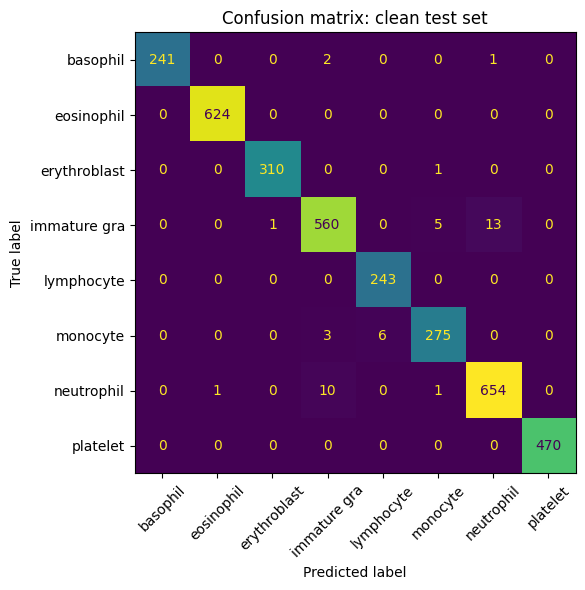

In [9]:
import json
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def predict(model, loader, shift=None):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            preds.append(model(prepare(x, shift)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

_ = load_checkpoint(model, None, "best.pt")
preds, labels = predict(model, loaders["test"])
test_acc = (preds == labels).mean()
per_class = [(preds[labels == c] == c).mean() for c in range(NUM_CLASSES)]
print(f"TEST accuracy: {test_acc*100:.2f}% | balanced accuracy: {np.mean(per_class)*100:.2f}%\n")
for c, a in enumerate(per_class):
    print(f"  {info['label'][str(c)][:24]:24s} {a*100:6.2f}%  (n={np.sum(labels == c)})")

short = [info["label"][str(c)].split("(")[0].strip()[:12] for c in range(NUM_CLASSES)]
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(labels, preds), display_labels=short).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix: clean test set")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "confusion_clean.png"), dpi=150); plt.show()

json.dump({"test_acc": float(test_acc), "test_bal_acc": float(np.mean(per_class)),
           "per_class": [float(a) for a in per_class]},
          open(os.path.join(RESULTS_DIR, "clean_test.json"), "w"), indent=1)

## Step 7: Simulated domain shifts

In practice, a model trained on images from one lab is deployed on images from another, acquired with different equipment and protocols. We simulate four common sources of variation, each at 5 severity levels:

- **Blur:** a microscope slightly out of focus (Gaussian blur).
- **Noise:** a noisier camera sensor or low light (Gaussian noise).
- **Stain:** a different staining protocol shifts the color balance (the red channel is scaled up and the blue channel down).
- **Contrast:** different illumination or camera settings reduce contrast.

Shifts are applied to the raw [0, 1] images *before* resizing and normalization, so they mimic changes at acquisition time.

These are synthetic approximations of real inter-lab variation, not a substitute for real multi-center data. Their advantage is control: we can vary one factor at a time and increase its severity gradually.

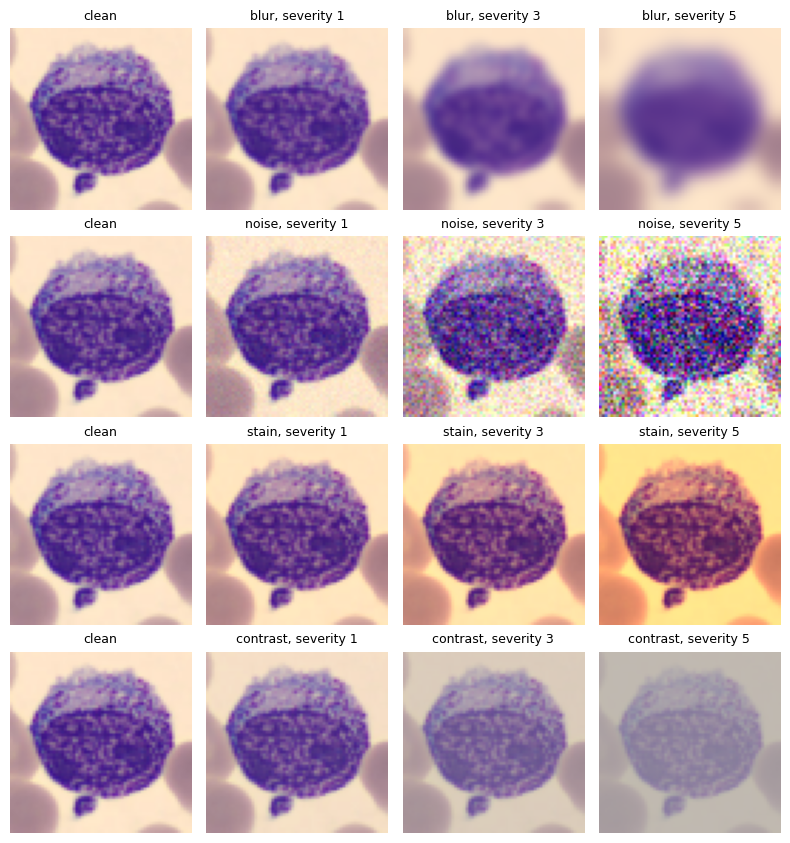

In [10]:
import torchvision.transforms.functional as TF

SHIFTS = ["blur", "noise", "stain", "contrast"]
SEVERITIES = [1, 2, 3, 4, 5]

def make_shift(kind, s):
    if kind == "blur":
        sigma = [0.5, 1.0, 1.5, 2.0, 3.0][s - 1]
        k = 2 * int(3 * sigma) + 1                       # kernel size must be odd
        return lambda x: TF.gaussian_blur(x, kernel_size=k, sigma=sigma)
    if kind == "noise":
        std = [0.02, 0.05, 0.10, 0.15, 0.20][s - 1]
        return lambda x: x + torch.randn_like(x) * std
    if kind == "stain":
        a = [0.05, 0.10, 0.15, 0.20, 0.30][s - 1]
        gains = torch.tensor([1 + a, 1.0, 1 - a], device=device).view(1, 3, 1, 1)
        return lambda x: x * gains                       # more red, less blue
    if kind == "contrast":
        c = [0.90, 0.75, 0.60, 0.45, 0.30][s - 1]
        def f(x):
            m = x.mean(dim=(1, 2, 3), keepdim=True)      # each image's average brightness
            return (x - m) * c + m                       # pull pixels toward the average
        return f

x, y = next(iter(loaders["test"]))
img = x[:1].to(device)
fig, axes = plt.subplots(len(SHIFTS), 4, figsize=(8, 8.5))
for r, kind in enumerate(SHIFTS):
    for c, s in enumerate([0, 1, 3, 5]):
        out = img if s == 0 else make_shift(kind, s)(img).clamp(0, 1)
        axes[r, c].imshow(out[0].permute(1, 2, 0).cpu()); axes[r, c].axis("off")
        axes[r, c].set_title("clean" if s == 0 else f"{kind}, severity {s}", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "shift_examples.png"), dpi=150); plt.show()

## Step 8: Accuracy under domain shift

We evaluate the trained model on the full test set under each shift (4 types × 5 severities = 20 evaluations). The model is **not retrained**: we measure how a model trained on one "lab" performs in an unfamiliar one.

For each setting we record:
- **Accuracy** and **balanced accuracy**.
- **Top-prediction share:** the fraction of test images assigned to the single most common predicted class. The true most common class makes up only ~19% of the test set. A much higher share means the model is *collapsing*: it stops distinguishing cells and labels most of them as one class.

The noise shift is random, so we reset the seed before every evaluation to keep results reproducible.

blur     severity 1: acc  97.40% | bal acc  97.36% | top-pred share  19.5%
blur     severity 2: acc  84.22% | bal acc  83.77% | top-pred share  19.2%
blur     severity 3: acc  65.24% | bal acc  63.75% | top-pred share  21.1%
blur     severity 4: acc  47.12% | bal acc  44.29% | top-pred share  35.7%
blur     severity 5: acc  29.14% | bal acc  26.87% | top-pred share  46.8%
noise    severity 1: acc  98.77% | bal acc  98.84% | top-pred share  19.6%
noise    severity 2: acc  98.71% | bal acc  98.74% | top-pred share  19.7%
noise    severity 3: acc  94.71% | bal acc  92.86% | top-pred share  20.0%
noise    severity 4: acc  80.36% | bal acc  71.70% | top-pred share  27.7%
noise    severity 5: acc  70.56% | bal acc  61.46% | top-pred share  25.3%
stain    severity 1: acc  98.71% | bal acc  98.78% | top-pred share  19.8%
stain    severity 2: acc  98.33% | bal acc  98.30% | top-pred share  20.3%
stain    severity 3: acc  97.11% | bal acc  96.73% | top-pred share  20.8%
stain    severity 4: acc 

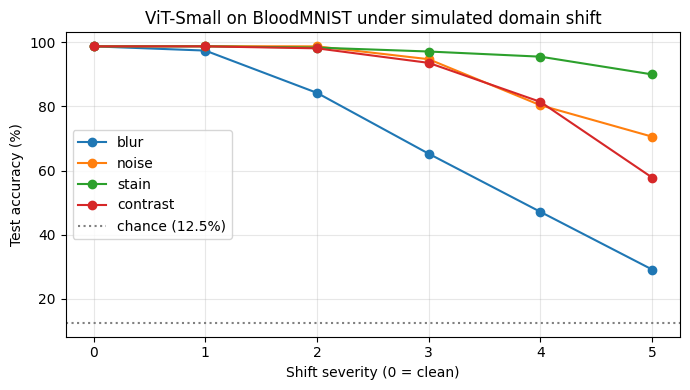

In [11]:
import pandas as pd

def summarize(p, l):
    acc = (p == l).mean()
    bal = np.mean([(p[l == c] == c).mean() for c in range(NUM_CLASSES)])
    top_share = np.bincount(p, minlength=NUM_CLASSES).max() / len(p)
    return float(acc), float(bal), float(top_share)

clean = summarize(preds, labels)
rows = [dict(shift="clean", severity=0, acc=clean[0], bal_acc=clean[1], top_share=clean[2])]

for kind in SHIFTS:
    for s in SEVERITIES:
        set_seed(0)
        p, l = predict(model, loaders["test"], make_shift(kind, s))
        acc, bal, top = summarize(p, l)
        rows.append(dict(shift=kind, severity=s, acc=acc, bal_acc=bal, top_share=top))
        print(f"{kind:8s} severity {s}: acc {acc*100:6.2f}% | bal acc {bal*100:6.2f}% | top-pred share {top*100:5.1f}%")

shift_df = pd.DataFrame(rows)
shift_df.to_csv(os.path.join(RESULTS_DIR, "shift_results.csv"), index=False)

plt.figure(figsize=(7, 4))
for kind in SHIFTS:
    d = shift_df[shift_df["shift"] == kind]
    plt.plot([0] + list(d["severity"]), [clean[0] * 100] + list(d["acc"] * 100), marker="o", label=kind)
plt.axhline(100 / NUM_CLASSES, ls=":", c="gray", label="chance (12.5%)")
plt.xlabel("Shift severity (0 = clean)"); plt.ylabel("Test accuracy (%)")
plt.title("ViT-Small on BloodMNIST under simulated domain shift")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "shift_curves.png"), dpi=150); plt.show()

## Step 9: Per-image normalization

Inspired by condition-aware normalization in time-series models, where each operating regime is normalized with its own statistics, we normalize **each image by its own per-channel mean and standard deviation** instead of fixed dataset-wide values.

**Hypothesis:** this makes the model invariant to stain shifts (each channel multiplied by a constant) and contrast shifts (pixels pulled toward the mean), because both are cancelled by standardization. It should *not* help with blur or noise, which change image structure rather than overall intensity.

This cell prepares the tools:
- `prepare` gets a switch, `NORM_MODE`, choosing between global normalization (baseline) and per-image normalization.
- `train_model` wraps the training loop from Step 5 into a reusable function with its own checkpoint names, so the new model never overwrites the baseline's checkpoints.
- `shift_eval` runs the full domain-shift evaluation from Step 8 for any model.

In [12]:
NORM_MODE = "global"          # "global" = baseline, "per_image" = new model

def prepare(x, shift=None):
    x = x.to(device, non_blocking=True)
    if shift is not None:
        x = shift(x).clamp(0, 1)
    x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
    if NORM_MODE == "per_image":
        m = x.mean(dim=(2, 3), keepdim=True)            # each image's own mean, per channel
        s = x.std(dim=(2, 3), keepdim=True)             # each image's own std, per channel
        return (x - m) / (s + 1e-6)
    return (x - mean_t) / std_t

def train_model(model, tag, epochs=EPOCHS):
    optimizer = torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=0.05)
    scaler = torch.amp.GradScaler("cuda")
    start, history = load_checkpoint(model, optimizer, f"{tag}_last.pt")
    history = history or {"train_loss": [], "val_acc": [], "val_bal_acc": []}
    best = max(history["val_acc"], default=0)
    for epoch in range(start, epochs):
        lr = float(BASE_LR * 0.5 * (1 + np.cos(np.pi * epoch / epochs)))
        for g in optimizer.param_groups:
            g["lr"] = lr
        model.train()
        total, t0 = 0.0, time.time()
        for x, y in loaders["train"]:
            y = y.to(device)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = criterion(model(prepare(x)), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total += loss.item() * len(y)
        va, vb = evaluate(model, loaders["val"])
        history["train_loss"].append(total / len(ds["train"]))
        history["val_acc"].append(va); history["val_bal_acc"].append(vb)
        print(f"[{tag}] epoch {epoch+1}/{epochs} | loss {history['train_loss'][-1]:.4f} | "
              f"val acc {va*100:.2f}% | {time.time()-t0:.0f}s")
        save_checkpoint(model, optimizer, epoch + 1, history, f"{tag}_last.pt")
        if va > best:
            best = va
            save_checkpoint(model, optimizer, epoch + 1, history, f"{tag}_best.pt")
    load_checkpoint(model, None, f"{tag}_best.pt")
    return model

def shift_eval(model, tag):
    rows = []
    for kind, s in [("clean", 0)] + [(k, s) for k in SHIFTS for s in SEVERITIES]:
        set_seed(0)
        p, l = predict(model, loaders["test"], None if kind == "clean" else make_shift(kind, s))
        acc, bal, top = summarize(p, l)
        rows.append(dict(model=tag, shift=kind, severity=s, acc=acc, bal_acc=bal, top_share=top))
    return pd.DataFrame(rows)

print("Helpers ready. NORM_MODE =", NORM_MODE)

Helpers ready. NORM_MODE = global


## Step 10: Per-image normalized model vs. baseline

We train a second ViT-Small with exactly the same settings as the baseline (same pretrained weights, seed, data order, epochs, and learning rate). The **only** difference is per-image normalization. Then we run the same 21-setting domain-shift evaluation and compare the two models side by side.

Changing only one thing at a time is what makes the comparison fair: any difference in results can be attributed to normalization.

No checkpoint 'perimage_last.pt' found, starting fresh.
[perimage] epoch 1/5 | loss 0.3011 | val acc 97.78% | 41s
Saved checkpoint: perimage_last.pt (epoch 1)
Saved checkpoint: perimage_best.pt (epoch 1)
[perimage] epoch 2/5 | loss 0.0714 | val acc 97.90% | 40s
Saved checkpoint: perimage_last.pt (epoch 2)
Saved checkpoint: perimage_best.pt (epoch 2)
[perimage] epoch 3/5 | loss 0.0547 | val acc 98.31% | 40s
Saved checkpoint: perimage_last.pt (epoch 3)
Saved checkpoint: perimage_best.pt (epoch 3)
[perimage] epoch 4/5 | loss 0.0325 | val acc 98.42% | 40s
Saved checkpoint: perimage_last.pt (epoch 4)
Saved checkpoint: perimage_best.pt (epoch 4)
[perimage] epoch 5/5 | loss 0.0219 | val acc 98.60% | 40s
Saved checkpoint: perimage_last.pt (epoch 5)
Saved checkpoint: perimage_best.pt (epoch 5)
Loaded checkpoint: perimage_best.pt (epoch 5)
model              baseline  per-image norm   gain
shift    severity                                 
clean    0            98.71           98.54  -0.18
blur 

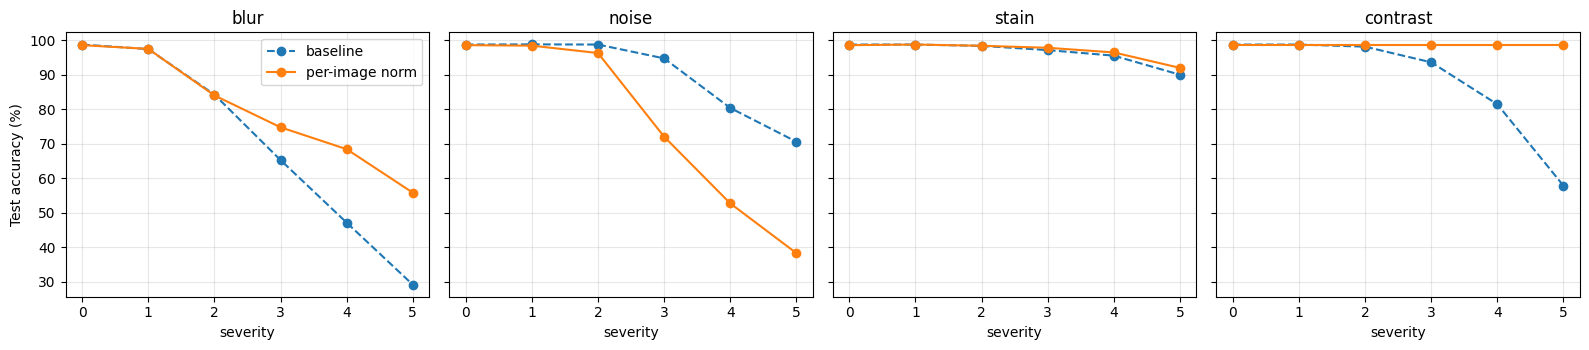

NORM_MODE is now: per_image


In [13]:
NORM_MODE = "per_image"

set_seed(0)
loaders["train"] = DataLoader(ds["train"], batch_size=64, shuffle=True, num_workers=2,
                              generator=torch.Generator().manual_seed(0))   # same data order as baseline
model_pi = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                             drop_rate=0.1, proj_drop_rate=0.1).to(device)
model_pi = train_model(model_pi, "perimage")

pi_df = shift_eval(model_pi, "per-image norm")
pi_df.to_csv(os.path.join(RESULTS_DIR, "shift_results_perimage.csv"), index=False)

base_df = shift_df.assign(model="baseline")
both = pd.concat([base_df, pi_df])
table = both.pivot_table(index=["shift", "severity"], columns="model", values="acc", sort=False) * 100
table["gain"] = table["per-image norm"] - table["baseline"]
print(table.round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, kind in zip(axes, SHIFTS):
    for name, df_, style in [("baseline", base_df, "o--"), ("per-image norm", pi_df, "o-")]:
        clean_acc = df_[df_["shift"] == "clean"]["acc"].iloc[0]
        d = df_[df_["shift"] == kind]
        ax.plot([0] + list(d["severity"]), [clean_acc * 100] + list(d["acc"] * 100), style, label=name)
    ax.set_title(kind); ax.set_xlabel("severity"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Test accuracy (%)"); axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "comparison.png"), dpi=150); plt.show()
print("NORM_MODE is now:", NORM_MODE)

## Step 11: Noise-robust per-image normalization

Per-image normalization failed under noise because noise inflates the image's standard deviation, the very statistic we normalize by. Here we compute the per-channel mean and standard deviation from a **blurred copy** of the image (Gaussian, σ = 1.5) and apply them to the **original** image.

Why this should work:
- **Noise** is random from pixel to pixel, so blurring averages most of it away. The statistics of the blurred copy barely change when noise is added.
- **Contrast and stain** shifts scale the image uniformly, and blurring preserves that scaling. So the blurred copy's statistics still change in exactly the same proportion, and the invariance to these shifts should survive.

The blurred copy is used **only to compute two numbers per channel**. The model still sees the original, sharp image.

No checkpoint 'robust_last.pt' found, starting fresh.
[robust] epoch 1/5 | loss 0.2972 | val acc 98.19% | 41s
Saved checkpoint: robust_last.pt (epoch 1)
Saved checkpoint: robust_best.pt (epoch 1)
[robust] epoch 2/5 | loss 0.0757 | val acc 96.61% | 41s
Saved checkpoint: robust_last.pt (epoch 2)
[robust] epoch 3/5 | loss 0.0583 | val acc 98.66% | 40s
Saved checkpoint: robust_last.pt (epoch 3)
Saved checkpoint: robust_best.pt (epoch 3)
[robust] epoch 4/5 | loss 0.0336 | val acc 98.66% | 41s
Saved checkpoint: robust_last.pt (epoch 4)
[robust] epoch 5/5 | loss 0.0220 | val acc 98.89% | 40s
Saved checkpoint: robust_last.pt (epoch 5)
Saved checkpoint: robust_best.pt (epoch 5)
Loaded checkpoint: robust_best.pt (epoch 5)
model              baseline  per-image norm  robust norm  robust vs baseline
shift    severity                                                           
clean    0            98.71           98.54        98.98                0.26
blur     1            97.40           97.46    

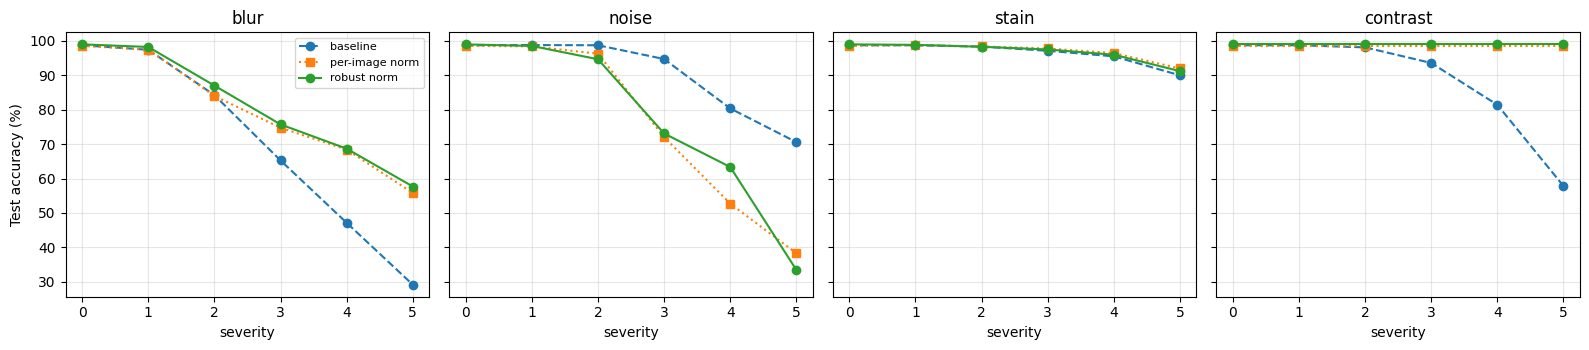

In [14]:
NORM_MODE = "robust"

def prepare(x, shift=None):
    x = x.to(device, non_blocking=True)
    if shift is not None:
        x = shift(x).clamp(0, 1)
    if NORM_MODE == "robust":
        xs = TF.gaussian_blur(x, kernel_size=9, sigma=1.5)     # blurred copy, for statistics only
        m = xs.mean(dim=(2, 3), keepdim=True)
        s = xs.std(dim=(2, 3), keepdim=True)
    x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
    if NORM_MODE == "robust":
        return (x - m) / (s + 1e-6)                            # applied to the original image
    if NORM_MODE == "per_image":
        m = x.mean(dim=(2, 3), keepdim=True)
        s = x.std(dim=(2, 3), keepdim=True)
        return (x - m) / (s + 1e-6)
    return (x - mean_t) / std_t

set_seed(0)
loaders["train"] = DataLoader(ds["train"], batch_size=64, shuffle=True, num_workers=2,
                              generator=torch.Generator().manual_seed(0))
model_rb = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                             drop_rate=0.1, proj_drop_rate=0.1).to(device)
model_rb = train_model(model_rb, "robust")

rb_df = shift_eval(model_rb, "robust norm")
rb_df.to_csv(os.path.join(RESULTS_DIR, "shift_results_robust.csv"), index=False)

all3 = pd.concat([base_df, pi_df, rb_df])
table = all3.pivot_table(index=["shift", "severity"], columns="model", values="acc", sort=False) * 100
table = table[["baseline", "per-image norm", "robust norm"]]
table["robust vs baseline"] = table["robust norm"] - table["baseline"]
print(table.round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, kind in zip(axes, SHIFTS):
    for name, df_, style in [("baseline", base_df, "o--"), ("per-image norm", pi_df, "s:"),
                             ("robust norm", rb_df, "o-")]:
        clean_acc = df_[df_["shift"] == "clean"]["acc"].iloc[0]
        d = df_[df_["shift"] == kind]
        ax.plot([0] + list(d["severity"]), [clean_acc * 100] + list(d["acc"] * 100), style, label=name)
    ax.set_title(kind); ax.set_xlabel("severity"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Test accuracy (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "comparison_3models.png"), dpi=150); plt.show()